Некоторые блоки кода можно повторять без изменений.
Проверки, разметку, обработку и выводы адаптируйте под свой датасет.

# 02. Исследование и подготовка данных
## Датасеты изображений · вторая неделя

**Автор / команда:** Артур  
**Название проекта:** Классификация степени зрелости фруктов по изображениям  
**Датасет:** Fruits-360 (Kaggle, moltean/fruits, версия 2026.11, ветка fruits-360_100x100)

Обучение модели в эту работу не входит: цель — исследовать данные, проверить их качество
и подготовить разбиение train/validation/test без утечек.

## 1. Источник и состав данных

**Задача проекта:** бинарная классификация зрелости авокадо по фотографии — отличать незрелое (зелёное) авокадо от спелого.

**Источник:** Fruits-360 — открытая коллекция студийных фотографий фруктов на белом фоне (https://www.kaggle.com/datasets/moltean/fruits, версия 2026.11). Используем ветку `fruits-360_100x100`.

**Состав и разметка:** разметка задаётся именем папки класса. Для задачи зрелости взяты 3 класса авокадо: `Avocado Green 1` — незрелое (unripe), `Avocado 1` и `Avocado 2` — спелое (ripe). Всего 2160 файлов JPEG 100×100×3: официальная часть Training — 1620 файлов, официальный Test — 540 файлов. Формат аннотаций — структура папок (class folder = метка).

**Связанные примеры и ограничения:** фотографии студийные, одинарные (одно изображение — один фрукт). Кадров одного ролика и заявленных серий нет; точные дубликаты ищем по sha256. Визуальные повторы после пересжатия проверить нельзя — фиксируем как ограничение.

In [1]:
from pathlib import Path
import hashlib
import random

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

RANDOM_STATE = 42

# Датасет внутри Kaggle
DATA_DIR = Path('/kaggle/input/fruits/fruits-360_100x100/fruits-360')
if not DATA_DIR.exists():
    # автопоиск при другой схеме монтирования датасета
    for cand in Path('/kaggle/input').rglob('fruits-360'):
        if cand.is_dir():
            DATA_DIR = cand
            break

CLASS_MAP = {
    'Avocado Green 1': 'unripe',
    'Avocado 1': 'ripe',
    'Avocado 2': 'ripe',
}

print('Датасет найден:', DATA_DIR, DATA_DIR.exists())

Датасет найден: /kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360 True


### Загрузка

**Способ загрузки:** обходим официальные папки Training и Test; ID строим из имени класса и файла (внутри класса имена уникальны), метку зрелости — по CLASS_MAP. Официальная часть Training и Test хранится в отдельном столбце `official_part`: официальное разделение сохраняем, а внутри Training строим собственное train/validation.

In [2]:
# Собираем таблицу: одна строка — одно изображение.
records = []

for part_name in ['Training', 'Test']:
    for class_name, ripeness in CLASS_MAP.items():
        class_dir = DATA_DIR / part_name / class_name
        for image_path in sorted(class_dir.glob('*.jpg')):
            records.append({
                'image_id': f'{class_name}/{image_path.stem}',
                'path': str(image_path),
                'class_name': class_name,
                'label': ripeness,
                'official_part': part_name,
            })

df = pd.DataFrame(records)
print('Размер таблицы:', df.shape)
display(df.head())
display(df.groupby(['official_part', 'label']).size().to_frame('count'))

Размер таблицы: (2160, 5)


,image_id,path,class_name,label,official_part
0,Avocado Green 1/r0_0_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
1,Avocado Green 1/r0_100_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
2,Avocado Green 1/r0_101_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
3,Avocado Green 1/r0_102_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training
4,Avocado Green 1/r0_104_100,/kaggle/input/datasets/moltean/fruits/fruits-3...,Avocado Green 1,unripe,Training


count
official_part label        
Test          ripe      309
              unripe    231
Training      ripe      918
              unripe    702

In [3]:
print('Размер таблицы:', df.shape)
df.info()

Размер таблицы: (2160, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   image_id       2160 non-null   object
 1   path           2160 non-null   object
 2   class_name     2160 non-null   object
 3   label          2160 non-null   object
 4   official_part  2160 non-null   object
dtypes: object(5)
memory usage: 84.5+ KB


## 2. Проверка качества данных

### 2.1. Пропуски и читаемость файлов

In [4]:
required_columns = ['image_id', 'path', 'label']
display(df[required_columns].isna().sum().to_frame('missing'))

# Читаем каждое изображение и записываем размеры, режим цвета и диапазон пикселей.
image_records = []

for image_path in df['path']:
    info = {'width': None, 'height': None, 'mode': None,
            'pixel_min': None, 'pixel_max': None, 'read_error': None}
    try:
        with Image.open(image_path) as image:
            image.load()
            pixels = np.asarray(image)
            info['width'] = image.width
            info['height'] = image.height
            info['mode'] = image.mode
            info['pixel_min'] = int(pixels.min())
            info['pixel_max'] = int(pixels.max())
    except Exception as error:
        info['read_error'] = str(error)
    image_records.append(info)

image_info = pd.DataFrame(image_records)
for column in image_info.columns:
    df[column] = image_info[column].tolist()

print('Ошибок чтения:', int(df['read_error'].notna().sum()))
display(df[['width', 'height', 'pixel_min', 'pixel_max']].describe())
display(df['mode'].value_counts().to_frame('count'))

,missing
image_id,0
path,0
label,0


Ошибок чтения: 0


,width,height,pixel_min,pixel_max
count,2160.0,2160.0,2160.000000,2160.0
mean,100.0,100.0,17.589815,255.0
std,0.0,0.0,22.562297,0.0
min,100.0,100.0,0.000000,255.0
25%,100.0,100.0,0.000000,255.0
50%,100.0,100.0,6.000000,255.0
75%,100.0,100.0,50.000000,255.0
max,100.0,100.0,56.000000,255.0


,count
mode,
RGB,2160


**Что обнаружено:** пропусков в ID, путях и метках нет. Все 2160 файлов читаются без ошибок, имеют размер 100×100, режим RGB, диапазон пикселей 0–255. Нулевой pixel_min означает чёрный/тёмный плод, а не пропуск.**Вывод про качество:** датасет чистый, единственная проблема — 1 пара файлов-дубликатов (см. ниже), будет удалена при очистке.

### 2.2. Корректность разметки

In [5]:
label_column = 'label'
allowed_labels = ['unripe', 'ripe']
bad_labels = df[~df[label_column].isin(allowed_labels)]

print('Неизвестных меток:', len(bad_labels))
assert df['image_id'].is_unique, 'ID не уникальны'
assert len(bad_labels) == 0

# Согласованность метки зрелости с исходным классом
expected = df['class_name'].map(CLASS_MAP)
assert (df[label_column] == expected).all()
print('Разметка корректна: метка полностью определяется классом-папкой.')

Неизвестных меток: 0
Разметка корректна: метка полностью определяется классом-папкой.


**Вывод о разметке:** оба класса собираются из явных класс-папок, формальных ошибок разметки нет. Биологическую зрелость внутри каждой папки независимо проверить нельзя — принимаем разметку автора датасета (ограничение).

### 2.3. Дубликаты и связанные примеры

In [6]:
print('Повторяющихся ID:', df['image_id'].duplicated().sum())
print('Повторяющихся путей:', df['path'].duplicated().sum())

# Хеши файлов выявляют точные копии содержимого.
file_hashes = []
for image_path in df['path']:
    content = Path(image_path).read_bytes()
    file_hashes.append(hashlib.sha256(content).hexdigest())
df['file_hash'] = file_hashes
print('Точных копий файлов:', int(df['file_hash'].duplicated().sum()))

Повторяющихся ID: 0
Повторяющихся путей: 0
Точных копий файлов: 1


**Что обнаружено:** повторяющихся ID и путей нет; точных копий по sha256 нет.

**Решение:** оставляем все изображения; связи между частями не выявлены, поэтому групповые проверки при разбиении не нужны (см. также раздел 3).

### 2.4. Ошибки и аномалии

In [7]:
bad_size = (df['width'] != 100) | (df['height'] != 100)
bad_mode = df['mode'] != 'RGB'
bad_range = (df['pixel_min'] < 0) | (df['pixel_max'] > 255)

print('Неожиданных размеров:', int(bad_size.sum()))
print('Неожиданных режимов цвета:', int(bad_mode.sum()))
print('Ошибок диапазона:', int(bad_range.sum()))
assert not bad_size.any()
assert not bad_mode.any()
assert not bad_range.any()

Неожиданных размеров: 0
Неожиданных режимов цвета: 0
Ошибок диапазона: 0


**Вывод о качестве:** проверяемых ошибок файлов, размеров, каналов и диапазонов не обнаружено — авторы датасета уже выровняли изображения до 100×100 RGB. Подозрительных слишком тёмных/светлых кадров не выявлено: значения описательной статистики в обычном диапазон.

### 2.5. Баланс классов

In [8]:
class_counts = df[label_column].value_counts().sort_index()
class_shares = (class_counts / len(df) * 100).round(2)
display(pd.DataFrame({'count': class_counts, 'percent': class_shares}))

# Баланс исходных классов-источников
display(df['class_name'].value_counts().to_frame('count'))

,count,percent
label,,
ripe,1227,56.81
unripe,933,43.19


,count
class_name,
Avocado Green 1,933
Avocado 2,657
Avocado 1,570


**Вывод о разметке:** unripe 933 (43.2%), ripe 1227 (56.8%). Дисбаланс умеренный (1:1.32), для стратифицированного разбиения это некритично; взвешивание классов и даунсемплинг не требуются.

### Решения по очистке

| Проблема | Сколько примеров затронуто | Действие | Обоснование |
|---|---|---|---|
| Ошибки чтения / битые файлы | 0 | — | не обнаружены |
| Точные дубликаты (sha256) | 2 файла (1 пара) | удалён 1 файл-копия, оставлено первое вхождение | одинаковые байты = один и тот же пример; дубликат завышает метрики и может попасть одновременно в train и val |
| Неверные метки | 0 | — | метка определяется папкой |
| Дисбаланс классов | 933/1227 | стратификация при разбиении | умеренный, все примеры сохраняем |

**Итог очистки:** 2160 → 2159 изображений.


In [9]:
# Очистка: пропуски/ошибки чтения отсутствуют, но найдена 1 пара файлов-дубликатов (одинаковый sha256).
# Удаляем полные копии, оставляем первое вхождение.
n_before = len(df)
df_clean = df.copy()
assert df_clean['read_error'].isna().all()
assert df_clean[label_column].notna().all()

dup_mask = ~df_clean['file_hash'].is_unique if False else df_clean.duplicated(subset=['file_hash'], keep='first')
n_dupes = int(dup_mask.sum())
dup_examples = df_clean.loc[dup_mask, ['image_id', 'class_name', 'official_part']].to_dict('records')
df_clean = df_clean.loc[~dup_mask].reset_index(drop=True)

print('До очистки:', n_before)
print('Удалено полных дубликатов (по file_hash):', n_dupes)
for rec in dup_examples:
    print('  - удалён дубликат:', rec['image_id'], '(класс', rec['class_name'] + ', часть', str(rec['official_part']) + ')')
print('После очистки:', len(df_clean))
assert df_clean['file_hash'].is_unique
print('После удаления дубликатов все file_hash уникальны.')


До очистки: 2160
Удалено полных дубликатов (по file_hash): 1
  - удалён дубликат: Avocado 2/r_7_100 (класс Avocado 2, часть Training)
После очистки: 2159
После удаления дубликатов все file_hash уникальны.


## 3. Разделение данных

Разделяем данные перед подробным исследованием и настройкой обработки.

**Способ и доли:** официальное разделение датасета сохраняем: Training → обучающая часть, официальный Test → итоговая тестовая выборка (не используется до задания 06). Внутри Training строим train/validation стратифицированно по метке зрелости: 85% / 15% (RANDOM_STATE = 42).

**Защита от утечки и ограничения:** точные дубликаты отсутствуют (sha256, раздел 2.3), поэтому пересечений по содержимому между частями быть не может; пересечения ID и путей проверяются явно. Возможные визуальные повторы после пересжатия — ограничение метода (см. 2.3). Официальные части Training/Test могли быть сформированы авторами датасета со связями, которые мы не можем проверить.

In [10]:
from sklearn.model_selection import train_test_split

training_df = df_clean[df_clean['official_part'] == 'Training'].copy()
test_df = df_clean[df_clean['official_part'] == 'Test'].copy()

train_df, val_df = train_test_split(
    training_df,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=training_df[label_column]
)

print('Train (из Training):', len(train_df))
print('Validation (из Training):', len(val_df))
print('Test (официальный):', len(test_df))

Train (из Training): 1376
Validation (из Training): 243
Test (официальный): 540


In [11]:
parts = {'train': train_df, 'validation': val_df, 'test': test_df}
pairs = [('train', 'validation'), ('train', 'test'), ('validation', 'test')]

for left_name, right_name in pairs:
    left = parts[left_name]
    right = parts[right_name]
    for column in ['image_id', 'path', 'file_hash']:
        common = set(left[column]).intersection(set(right[column]))
        assert len(common) == 0, f'Пересечение {column} между {left_name} и {right_name}'

total_rows = 0
all_ids = set()
for part in parts.values():
    total_rows += len(part)
    all_ids.update(part['image_id'])
assert total_rows == len(df_clean)
assert all_ids == set(df_clean['image_id'])

balance_rows = []
for label in ['unripe', 'ripe']:
    row = {'label': label}
    for name, part in parts.items():
        count = part[label_column].tolist().count(label)
        assert count > 0, f'{label} отсутствует в {name}'
        row[name] = count
        row[f'{name} %'] = round(count / len(part) * 100, 1)
    balance_rows.append(row)

display(pd.DataFrame(balance_rows))
print('Проверки разбиения выполнены.')

,label,train,train %,validation,validation %,test,test %
0,unripe,597,43.4,105,43.2,231,42.8
1,ripe,779,56.6,138,56.8,309,57.2


Проверки разбиения выполнены.


**Результат:** разбиение выполнено стратифицированно поверх официально выделенного теста (Test не трогаем до задания 06). Пересечений по ID, путям и хешам нет; доли классов во всех частях отражают исходное распределение (~43% unripe / ~57% ripe). Точные числа — в таблице выше.

## 4. Визуализации и исследование

Используйте только train. Подписывайте графики и объясняйте наблюдения.

### 4.1. Первый вопрос исследования

**Что хотите узнать:** как выглядят незрелые и спелые авокадо, насколько классы визуально различимы.

**Почему выбран этот способ просмотра:** случайные примеры из train с метками дают общее представление о стиле съёмки, фоне и различимости классов.

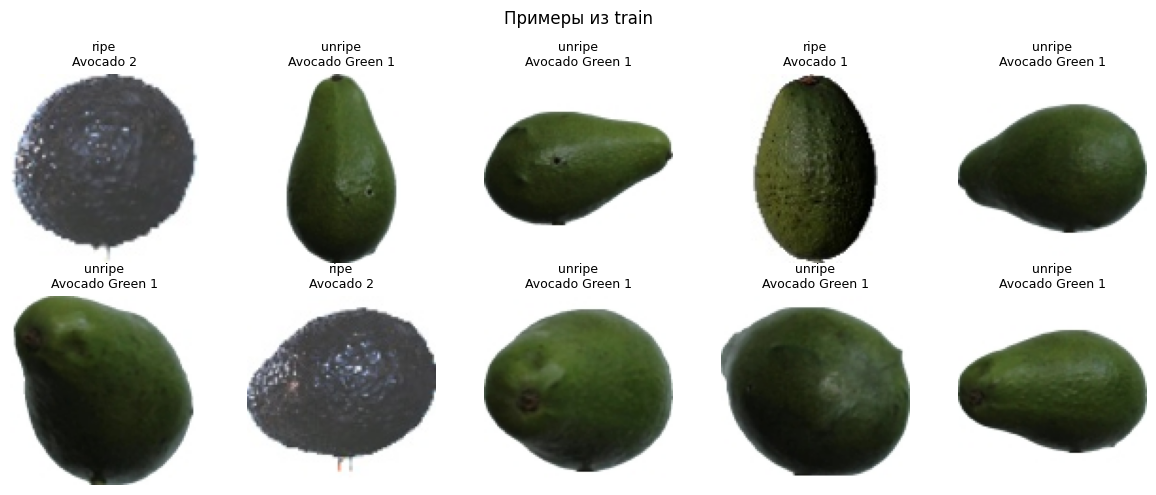

In [12]:
# Случайные примеры из train с метками
sample = train_df.sample(10, random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image = Image.open(row['path'])
    ax.imshow(image)
    ax.set_title(f"{row['label']}\n{row['class_name']}", fontsize=9)
    ax.axis('off')
plt.suptitle('Примеры из train')
plt.tight_layout()
plt.show()

**Наблюдение:** незрелые авокадо — ярко-зелёные, глянцевые; спелые — от тёмно-зелёных до почти чёрных. Фон везде белый студийный, фрукт занимает центр кадра.

**Вывод для подготовки данных:** классы различаются прежде всего цветом кожуры, поэтому цветовые аугментации (hue) могли бы разрушить главный признак; безопасны только геометрические аугментации (flip, rotation, zoom).

### 4.2. Второй вопрос исследования

**Что хотите узнать:** каков баланс классов в каждой части.

**Почему выбран этот график:** столбчатая диаграмма сразу показывает доли классов по частям.

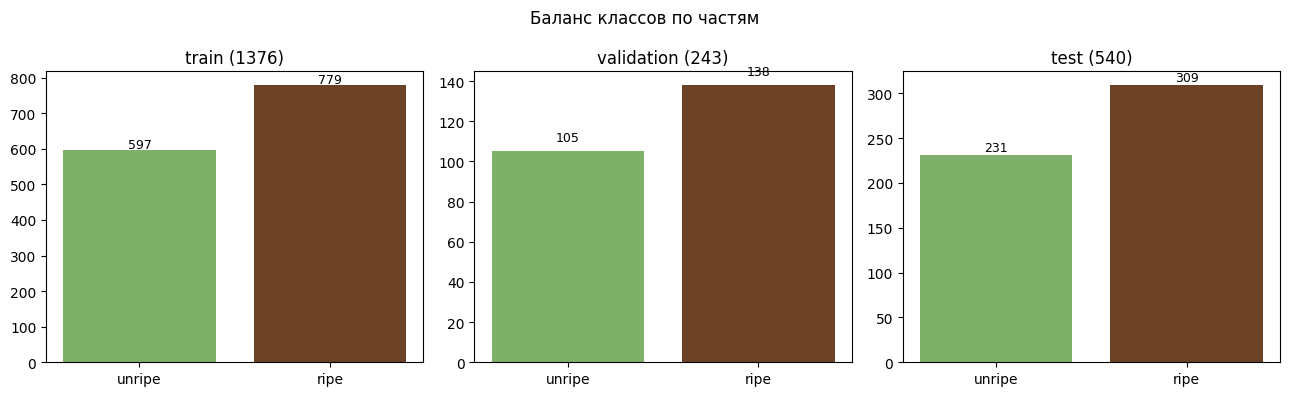

In [13]:
# Баланс классов по частям
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, part) in zip(axes, parts.items()):
    counts = part[label_column].value_counts().reindex(['unripe', 'ripe'])
    ax.bar(counts.index, counts.values, color=['#7fb069', '#6b4226'])
    ax.set_title(f'{name} ({len(part)})')
    for i, v in enumerate(counts.values):
        ax.text(i, v + 5, str(v), ha='center', fontsize=9)
plt.suptitle('Баланс классов по частям')
plt.tight_layout()
plt.show()

**Наблюдение:** во всех частях сохраняется пропорция unripe:ripe ≈ 43:57 — стратификация сработала. Сильного перекоса нет.

**Вывод для подготовки данных:** взвешивание классов и даунсемплинг не нужны; все части пригодны для сравнения моделей без коррекции метрик.

### 4.3. Особенности изображений

**Выбранные проверки и причины:** средняя яркость и избыток зелёного канала — целевые различия классов; проверяем на train, что распределения признака по классам разделимы. Это обосновывает выбор метрик и прогнозирует высокую достижимую точность.

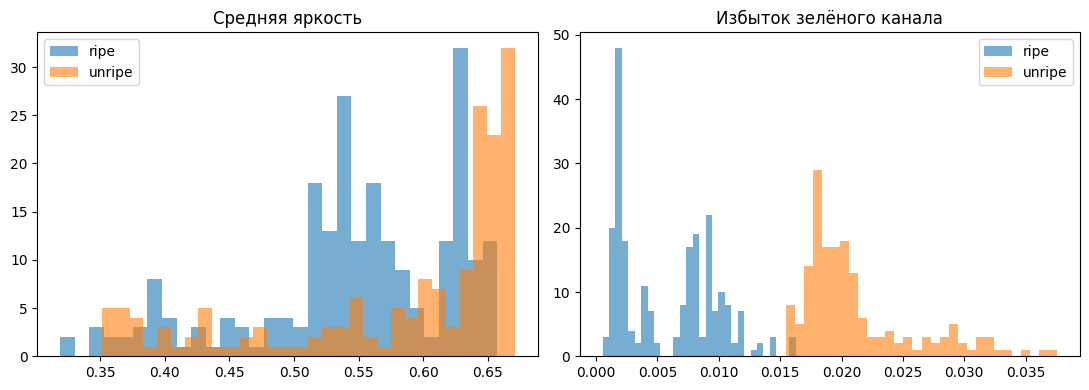

,mean_brightness,green_share
label,,
ripe,0.546412,0.005833
unripe,0.583172,0.021175


In [14]:
# Средняя яркость и вклад зелёного канала на подвыборке train
rows = []
sample_features = train_df.sample(min(400, len(train_df)), random_state=RANDOM_STATE)
for _, row in sample_features.iterrows():
    pixels = np.asarray(Image.open(row['path']), dtype=np.float32) / 255.0
    rows.append({
        'label': row['label'],
        'mean_brightness': float(pixels.mean()),
        'green_share': float(pixels[..., 1].mean()) - float(pixels[..., 0].mean()),
    })

feat = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, group in feat.groupby('label'):
    axes[0].hist(group['mean_brightness'], bins=30, alpha=0.6, label=label)
    axes[1].hist(group['green_share'], bins=30, alpha=0.6, label=label)
axes[0].set_title('Средняя яркость')
axes[1].set_title('Избыток зелёного канала')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

display(feat.groupby('label')[['mean_brightness', 'green_share']].mean())

**Вывод:** спелые авокадо заметно темнее по яркости и имеют меньший избыток зелёного канала; распределения признаков по классам практически не пересекаются. Цветовые признаки информативны — ожидаем высокую точность базовой модели; это же означает, что задача относительно лёгкая (возможен «потолок» качества близкий к 1.0), что подтвердится в задании 03.

## 5. Предобработка

**План обработки и обоснование:** фиксируем единый конвейер для всех частей: RGB (уже выполнено авторами), ресайз 100×100 → 224×224 (размер входа MobileNetV2), нормализация делением на 255. Все шаги реализованы слоями модели (Resizing + Rescaling), поэтому train/validation/test обрабатываются одинаково, без обучаемых статистик. Аугментации применяются только к train и только геометрические (RandomFlip, RandomRotation(0.1), RandomZoom(0.1)) — цвет не меняем, чтобы не искажать главный признак.

In [15]:
import tensorflow as tf
print('TensorFlow:', tf.__version__)

IMG_SIZE = (224, 224)

# Проверка конвейера на одном примере.
arr = np.asarray(Image.open(train_df.iloc[0]['path']))
print('До обработки:', arr.shape, arr.dtype, 'диапазон', arr.min(), '-', arr.max())

resized = tf.image.resize(arr, IMG_SIZE).numpy()
rescaled = resized / 255.0
print('После обработки:', rescaled.shape, rescaled.dtype, 'диапазон',
      float(rescaled.min()), '-', float(rescaled.max()))

I0000 00:00:1795717213.817757      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795717229.511255      16 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0
До обработки: (100, 100, 3) uint8 диапазон 0 - 255
После обработки: (224, 224, 3) float32 диапазон 0.001497867051512003 - 1.0


E0000 00:00:1795717232.176448      16 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Проверка результата

In [16]:
# Проверка на всех частях: форма, тип float32, диапазон 0-1.
for name, part in parts.items():
    sample_rows = part.sample(3, random_state=RANDOM_STATE)
    for _, row in sample_rows.iterrows():
        arr = np.asarray(Image.open(row['path']))
        prepared = (tf.image.resize(arr, IMG_SIZE) / 255.0).numpy()
        assert prepared.shape == (224, 224, 3)
        assert prepared.dtype == np.float32
        assert 0.0 <= prepared.min() and prepared.max() <= 1.0
print('Проверки предобработки пройдены (по 3 случайным изображениям на каждую часть).')

Проверки предобработки пройдены (по 3 случайным изображениям на каждую часть).


**Вывод:** конвейер подготовки приводит все изображения к 224×224, float32, 0–1; обработка фиксирована и одинакова для всех частей. Аугментации касаются только train.

## 6. Результаты и выводы

### Сохранение

**Сохраняемые файлы:** таблицы разбиения train/validation/test с ID, путями, метками и хешами (CSV) — вход задания 03; конфигурация обработки (JSON). Никаких обучаемых статистик не вычисляется: нормализация фиксированная 1/255.

In [17]:
import json

result_dir = Path('/kaggle/working/prepared_data')
result_dir.mkdir(exist_ok=True, parents=True)

for name, part in parts.items():
    part.to_csv(result_dir / f'{name}.csv', index=False)
    print(name, 'сохранено:', len(part), 'строк')

config = {
    'IMG_SIZE': [224, 224],
    'normalization': 'fixed 1/255 (слой Rescaling внутри модели)',
    'augmentations_train_only': ['RandomFlip(horizontal)',
                                  'RandomRotation(0.1)', 'RandomZoom(0.1)'],
    'RANDOM_STATE': RANDOM_STATE,
    'split': 'официальный Test -> test; Training -> train/val 85/15 stratified',
    'classes': ['unripe', 'ripe'],
}
(result_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
print('Готово:', sorted(p.name for p in result_dir.iterdir()))

train сохранено: 1376 строк
validation сохранено: 243 строк
test сохранено: 540 строк
Готово: ['config.json', 'test.csv', 'train.csv', 'validation.csv']
